In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV Version:", cv2.__version__)

OpenCV Version: 5.0.0


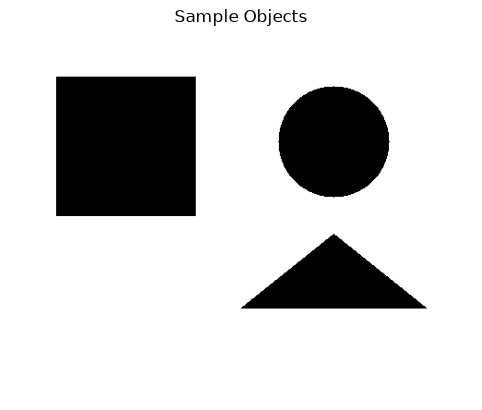

In [2]:
image = np.ones((400, 500, 3), dtype=np.uint8) * 255

# Rectangle
cv2.rectangle(image, (50, 50), (200, 200), (0, 0, 0), -1)

# Circle
cv2.circle(image, (350, 120), 60, (0, 0, 0), -1)

# Triangle
points = np.array([[250, 300], [350, 220], [450, 300]], np.int32)

cv2.fillPoly(image, [points], (0, 0, 0))

cv2.imwrite("objects.jpg", image)

plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Sample Objects")
plt.axis("off")
plt.show()

In [3]:
## Edge Detection

Edge Detection is used to identify boundaries
of objects in an image.

OpenCV provides the Canny() function for edge detection.

SyntaxError: invalid syntax (3671756234.py, line 3)

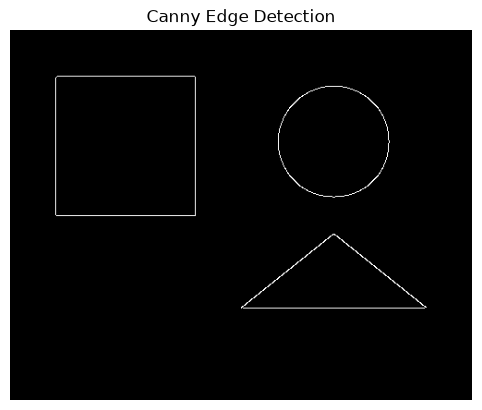

In [4]:
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

edges = cv2.Canny(gray, 100, 200)

plt.imshow(edges, cmap="gray")
plt.title("Canny Edge Detection")
plt.axis("off")
plt.show()

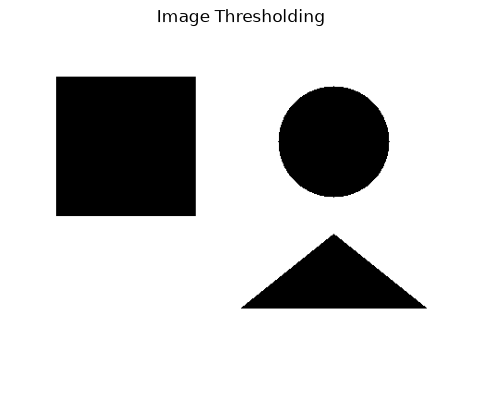

In [5]:
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

_, threshold_image = cv2.threshold(
    gray,
    127,
    255,
    cv2.THRESH_BINARY
)

plt.imshow(threshold_image, cmap="gray")
plt.title("Image Thresholding")
plt.axis("off")
plt.show()

Blobs Detected: 3


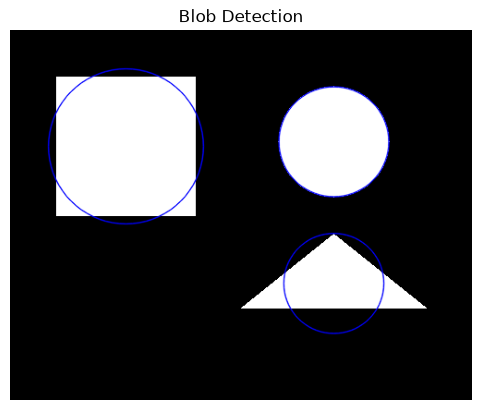

In [6]:
# Convert black objects into white blobs
blob_input = cv2.bitwise_not(threshold_image)

# Set blob detector parameters
params = cv2.SimpleBlobDetector_Params()

params.filterByArea = True
params.minArea = 100
params.maxArea = 50000

params.filterByColor = True
params.blobColor = 255

params.filterByCircularity = False
params.filterByConvexity = False
params.filterByInertia = False

# Create detector
detector = cv2.SimpleBlobDetector_create(params)

# Detect blobs
keypoints = detector.detect(blob_input)

# Draw detected blobs
result = cv2.drawKeypoints(
    blob_input,
    keypoints,
    None,
    (0, 0, 255),
    cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

print("Blobs Detected:", len(keypoints))

plt.imshow(result, cmap="gray")
plt.title("Blob Detection")
plt.axis("off")
plt.show()

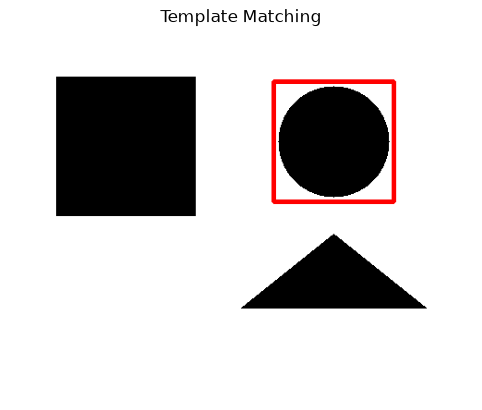

Matching Score: 0.9999999403953552


In [7]:
# Create template from the circle in the sample image
template = gray[55:185, 285:415]

# Perform template matching
result = cv2.matchTemplate(
    gray,
    template,
    cv2.TM_CCOEFF_NORMED
)

# Find best matching location
min_val, max_val, min_loc, max_loc = cv2.minMaxLoc(result)

height, width = template.shape

top_left = max_loc
bottom_right = (top_left[0] + width, top_left[1] + height)

# Draw rectangle around matched object
output = image.copy()

cv2.rectangle(
    output,
    top_left,
    bottom_right,
    (0, 0, 255),
    3
)

plt.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
plt.title("Template Matching")
plt.axis("off")
plt.show()

print("Matching Score:", max_val)

Total Objects Detected: 3


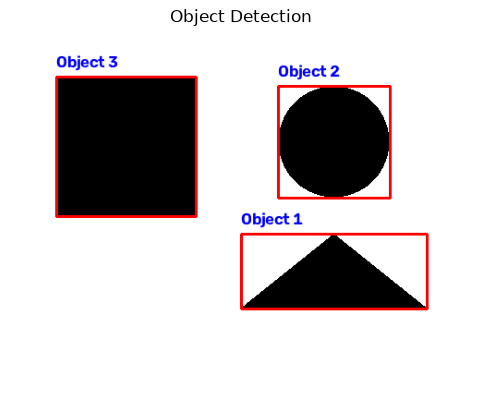

In [8]:
# Find object contours
contours, hierarchy = cv2.findContours(
    blob_input,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

output = image.copy()

object_count = 0

for contour in contours:
    area = cv2.contourArea(contour)

    if area > 500:
        x, y, w, h = cv2.boundingRect(contour)

        object_count += 1

        cv2.rectangle(
            output,
            (x, y),
            (x + w, y + h),
            (0, 0, 255),
            2
        )

        cv2.putText(
            output,
            f"Object {object_count}",
            (x, y - 10),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6,
            (255, 0, 0),
            2
        )

print("Total Objects Detected:", object_count)

plt.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
plt.title("Object Detection")
plt.axis("off")
plt.show()